In [155]:
#Create a model that predicts the selling price of the car. Split the data for training purposes.

In [156]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import LinearRegression



In [157]:
#Todo
# 1. Filter out necessary features
# 2. Filter the data
# 2.5 Plot data to figure out which model to use 
# 3. Split the data into testing and training
# 4. Fit the model
# 5. predict and test the model

In [158]:
car_data = pd.read_csv('car_dataset.csv')
car_data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [159]:
car_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


<Axes: >

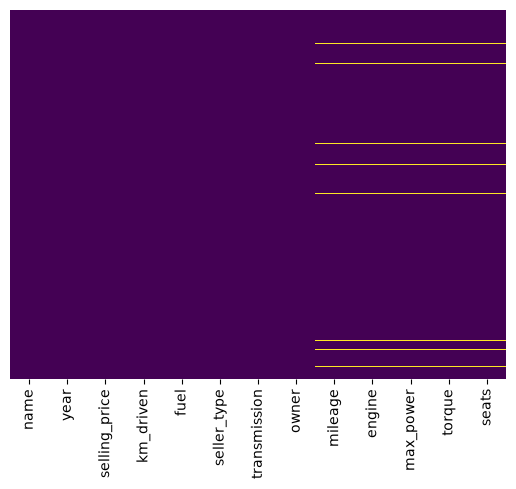

In [160]:
missing_values = car_data.isnull()
sns.heatmap(data= missing_values, yticklabels=False, cbar=False, cmap='viridis')

<Axes: xlabel='fuel', ylabel='count'>

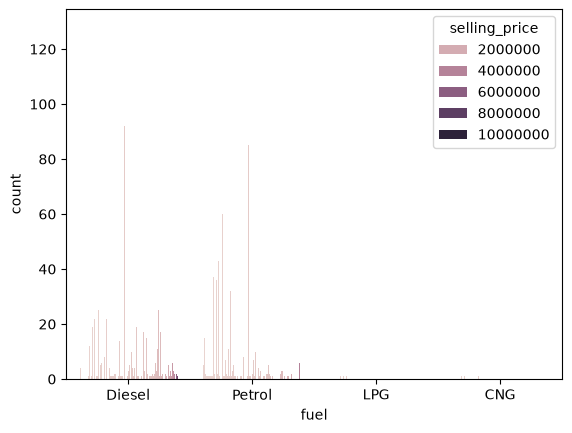

In [161]:
sns.countplot(x='fuel', data=car_data, hue='selling_price')

In [162]:
#This is probably not a predictor of selling price

<Axes: xlabel='owner', ylabel='count'>

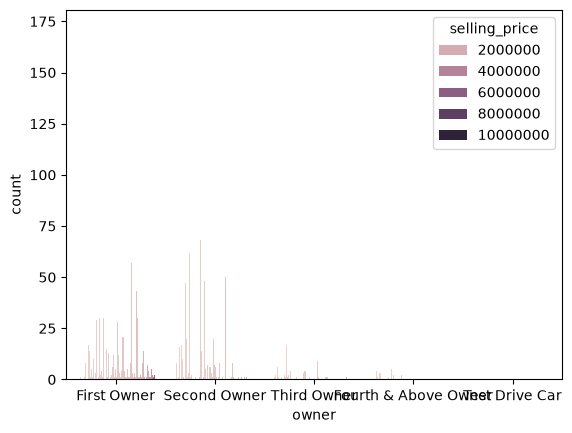

In [163]:
sns.countplot(x='owner', data=car_data, hue='selling_price',)

In [164]:
#Probably a predictor of selling price

In [165]:
car_data.dropna(inplace=True)

<Axes: >

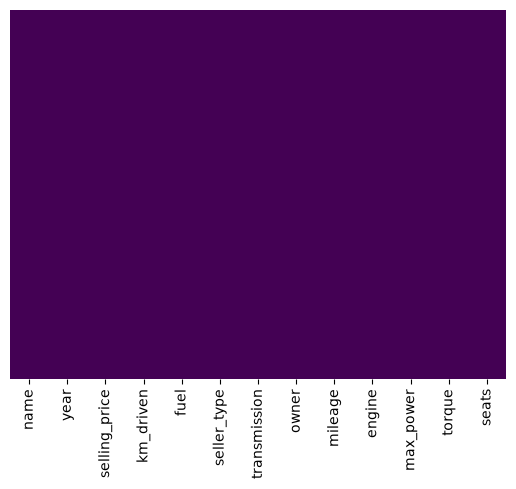

In [166]:
missing_values = car_data.isnull()
sns.heatmap(data= missing_values, yticklabels=False, cbar=False, cmap='viridis')

In [167]:
car_data['max_power'] = car_data['max_power'].str.extract(r'(\d+\.?\d*)').astype(float)
car_data['engine'] = car_data['engine'].str.extract(r'(\d+\.?\d*)').astype(float)
car_data['mileage'] = car_data['mileage'].str.extract(r'(\d+\.?\d*)').astype(float)
car_data['torque'] = car_data['torque'].str.extract(r'(\d+\.?\d*)').astype(float)

fuel = pd.get_dummies(car_data['fuel'], drop_first=True)
seller_type = pd.get_dummies(car_data['seller_type'],drop_first=True)
owner = pd.get_dummies(car_data['owner'], drop_first=True)
transmission = pd.get_dummies(car_data['transmission'],drop_first=True)

car_data = pd.concat([car_data, fuel, seller_type, owner, transmission], axis=1)


In [168]:
#columns that are to be dropped
car_data.columns
car_data.drop(['name', 'seller_type', 'fuel', 'transmission', 'seats', 'owner', 'torque'], axis=1, inplace=True)
car_data.columns

Index(['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power',
       'Diesel', 'LPG', 'Petrol', 'Individual', 'Trustmark Dealer',
       'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner',
       'Manual'],
      dtype='str')

In [169]:
#Training data
X = car_data[['year','km_driven', 'mileage', 'engine', 'max_power',
       'Diesel', 'LPG', 'Petrol', 'Individual', 'Trustmark Dealer',
       'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner',
       'Manual']]
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = car_data['selling_price']

In [170]:
#split the data set with 70% training 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=100)

In [189]:
#enet regression model

eNet = ElasticNet(alpha=1, l1_ratio=0.8)
eNet.fit(X_train, y_train)

,"l1_ratio l1_ratio: float, default=0.5The ElasticNet mixing parameter, with ``0 <= l1_ratio <= 1``. For``l1_ratio = 0`` the penalty is an L2 penalty. ``For l1_ratio = 1`` itis an L1 penalty. For ``0 < l1_ratio < 1``, the penalty is acombination of L1 and L2.",0.8
,"alpha alpha: float, default=1.0Constant that multiplies the penalty terms. Defaults to 1.0.See the notes for the exact mathematical meaning of thisparameter. ``alpha = 0`` is equivalent to an ordinary least square,solved by the :class:`LinearRegression` object. For numericalreasons, using ``alpha = 0`` with the ``Lasso`` object is not advised.Given this, you should use the :class:`LinearRegression` object.",1
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If ``False``, thedata is assumed to be already centered.",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.Check :ref:`an example on how to use a precomputed Gram Matrix in ElasticNet<sphx_glr_auto_examples_linear_model_plot_elastic_net_precomputed_gram_matrix_with_weighted_samples.py>`for details.",False
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [190]:
#Linear regression model

linRegModel = LinearRegression()
linRegModel.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[ 125879.96, -48327.78, 51318.71,..., 66383.41, -10490.39,-161114.5 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.515e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,15
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](15,)","[127.55,116.54, 98.55,..., 39.52, 28.4 , 8.04]"


In [191]:
#Testing both

eNet.predict(X_test)
linRegModel.predict(X_test)

array([ 710433.75095863,  314839.36662532,  785237.11625069, ...,
       1812849.79569137, -415609.85811245,  153160.93752965],
      shape=(2372,))

In [192]:
eNet.score(X_test, y_test)


0.6595209180643954

In [193]:
linRegModel.score(X_test, y_test)

0.6686919526729072